
# Predicción de precios Bogotá Notebook reproducible

Esta versión reorganiza el notebook desde la sección de **Feature Engineering** en adelante, priorizando:

- **Legibilidad**: bloques compactos, nombres consistentes y menos celdas exploratorias.
- **Reproducibilidad**: configuración centralizada, funciones reutilizables y flujo secuencial.

> **Supuesto de entrada:** ya existe el dataframe `df_inm_deflact` en memoria o un archivo parquet equivalente.


## 1. Configuración e imports

In [ ]:

from __future__ import annotations

from pathlib import Path
import warnings
import math
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import learning_curve, KFold

from xgboost import XGBRegressor
import shap

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)


In [ ]:

# Configuración general
TARGET = 'precio_deflactado'
DATE_COL = 'fecha_mes'
TRAIN_END = '2024-12-01'
RANDOM_STATE = 42
RESULTS_DIR = Path('results')
LASSO_DIR = Path('lasso')
MODELS_DIR = Path('models')

for folder in [RESULTS_DIR / 'metrics', RESULTS_DIR / 'plots', RESULTS_DIR / 'shap', LASSO_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DROP_LEAKAGE_COLS = [
    '$m2', 'Rango $', 'Rango $m2', 'Rango $E', 'Rango $M2E',
    'Valor SMLV', 'Observación valor SMLV'
]

ID_COLS = ['Codproyecto', 'Codinmueble', 'Proyecto', 'Vende', 'Codvende']
DROP_MODEL_COLS = ['Codinmueble', 'Proyecto', 'Vende', 'Codvende', 'P', 'log_precio_deflactado']
GROUP_COL_CANDIDATES = ['Codproyecto','Zona', 'Sub Zona', 'Estrato']


## 2. Carga del dataset base

In [ ]:

# Opción A: usar el dataframe existente en memoria
try:
    df_inm_deflact
except NameError:
    # Opción B: cargar desde parquet si no está en memoria
    PARQUET_PATH = '/content/inmuebles_deflactados.parquet'
    df_inm_deflact = pd.read_parquet(PARQUET_PATH)

print(df_inm_deflact.shape)
df_inm_deflact.head(2)


(705824, 89)


,Codproyecto,Codinmueble,Proyecto,Vende,Codvende,Zona,Sub Zona,Estrato,Tipo,Area,Alc.,Baños Completos,Baños sin Terminar,# Gar.,Area Patio,Area Lote / Jardin,Area Terraza o Balcon,Estudio/Estar,Depósito,Garaje,Valor Garaje,Tipo Garaje Adicional,Valor Garaje Adicional,Tipo VIS,Prev.,Const.,Ter.,V.Proy. Mes,N. Proy. Mes,$m2,V.Acum.,V. Total Inm. Tipo,Oferta Total Inm.,Oferta Total Proyecto,V. Total Proyecto,V. Prom. Inm,Cam. $,V. 3 Meses,V. 3 Proyecto,Venta Trim.,Venta Mes,D. Proy. Mes Ant.,D.Proy. Mes,Inm. Tipo Activo,V. Acum. Proy.,V. Prom Proy.,Of.Ac.,V. Mes $ Inm. Tipo,V. Mes $ Proy.,Area Of. Inm. Tipo,Area Of. Proyecto,$ Of. Inm. Tipo,$ Of. Proyecto,$ Prom. Oferta m2,V. Año $ Inm. Tipo,V. Año $ Proy.,Rango $,Rango m2,Rango $m2,Rango $E,Rango M2E,Rango $M2E,Rango Estudio Com.,$ Prom,A. Prom.,$m2Pr.,Verificacion Estado,Oferta Lanzada M2 Inm.,Oferta Lanzada M2 Proy.,Ventas Año Un.,Ventas Año $ (mm),Estado,Valor SMLV,Observación valor SMLV,fecha_mes,D,N,P,V,Municipio,Barrio,Latitud (Coordenada Real),Longitud\n(Coordenada Real),Certificacion Sostenible,zona_ipvn,ipc_rebase_100,ipc_real_rebase_100,factor,precio_deflactado
36,062f50753b,589f5ed0ac,4bc53755fe,3df22e926a,BCARA,Sabana,Mosquera,3,Casa,72.00,2,2,0,1,0,0.00,0,No,No,Sencillo,6500000,No,$0,Vis,0,0,0,0,0,"333,333.33",0,0,0,545,545,0.00,0.00,0,0,6963,1896,0,0,No,0,0.00,0,0.00,0.00,0.00,0.00,0.00,0.00,N.A.,0.00,0.00,VIP - VIS,50 - 75,0 - 2000,1,1,1,0,0,0.00,0.00,0,0.00,"44,565.00",0,0.00,Term./,NaN,<NA>,2023-01-01,NaN,NaN,"24,000,000.00",0.00,Mosquera,Mosquera,4.71,-74.23,No,Alrededores,92.59,103.47,1.12,"26,820,414.65"
37,062f50753b,589f5ed0ac,4bc53755fe,3df22e926a,BCARA,Sabana,Mosquera,3,Casa,72.00,2,2,0,1,0,0.00,0,No,No,Sencillo,6500000,No,$0,Vis,0,0,0,0,0,"333,333.33",0,0,0,545,545,0.00,0.00,0,0,6963,1896,0,0,No,0,0.00,0,0.00,0.00,0.00,0.00,0.00,0.00,N.A.,0.00,0.00,VIP - VIS,50 - 75,0 - 2000,1,1,1,0,0,0.00,0.00,0,0.00,"44,565.00",0,0.00,Term./,NaN,<NA>,2023-02-01,NaN,NaN,"24,000,000.00",0.00,Mosquera,Mosquera,4.71,-74.23,No,Alrededores,93.58,102.63,1.10,"26,322,225.37"


## 3. Funciones auxiliares

In [ ]:

def safe_log(series: pd.Series) -> pd.Series:
    return np.where(series > 0, np.log(series), np.nan)


def clean_numeric_text_columns(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    df = df.copy()
    for col in columns:
        if col in df.columns:
            df[col] = pd.to_numeric(
                df[col].astype(str).str.replace(',', '.', regex=False).str.strip(),
                errors='coerce'
            )
    return df


def add_feature_engineering(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df = df.drop(columns=[c for c in DROP_LEAKAGE_COLS if c in df.columns], errors='ignore')
    df = clean_numeric_text_columns(df, ['Area Patio', 'Area Terraza o Balcon', 'Area Lote / Jardin'])

    df['log_precio_deflactado'] = safe_log(df[TARGET])
    df['log_area'] = safe_log(df['Area'])

    df['area_por_alcoba'] = np.where(df['Alc.'] > 0, df['Area'] / df['Alc.'], np.nan)
    df['baños_totales'] = df['Baños Completos'] + 0.5 * df['Baños sin Terminar']

    df['tiene_patio'] = (df['Area Patio'] > 0).astype(int)
    df['tiene_terraza'] = (df['Area Terraza o Balcon'] > 0).astype(int)
    df['tiene_estudio'] = df['Estudio/Estar'].isin([
        'Estudio', 'Estar', 'Estudio/Estar ', 'Disponible/estudio', 'Espacio', 'Estar y Estudio'
    ]).astype(int)

    df['total_unidades'] = df['Prev.'] + df['Const.'] + df['Ter.']
    df['porc_terminadas'] = np.where(df['total_unidades'] > 0, df['Ter.'] / df['total_unidades'], np.nan)
    df['porc_disponibles'] = np.where(df['total_unidades'] > 0, df['D'] / df['total_unidades'], np.nan)

    df = df.replace([np.inf, -np.inf], np.nan)
    return df


def build_modeling_dataset(df: pd.DataFrame) -> pd.DataFrame:
    df_model = df.copy()
    df_model[DATE_COL] = pd.to_datetime(df_model[DATE_COL])
    df_model = df_model.drop(columns=[c for c in DROP_MODEL_COLS if c in df_model.columns], errors='ignore')
    return df_model


def temporal_split(df: pd.DataFrame, split_date: str = TRAIN_END) -> tuple[pd.DataFrame, pd.DataFrame]:
    split_date = pd.to_datetime(split_date)
    train = df[df[DATE_COL] <= split_date].copy()
    test = df[df[DATE_COL] > split_date].copy()
    return train, test


def detect_feature_groups(df_train: pd.DataFrame) -> tuple[list[str], list[str]]:
    numeric_cols = df_train.select_dtypes(include=[np.number]).columns.tolist()
    numeric_features = [c for c in numeric_cols if c != TARGET]

    categorical_candidates = df_train.select_dtypes(include=['object', 'category']).columns.tolist()
    categorical_features = [c for c in categorical_candidates if c not in [DATE_COL]]

    return numeric_features, categorical_features


def build_preprocessor(numeric_features: list[str], categorical_features: list[str]) -> ColumnTransformer:
    num_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
        ('scaler', StandardScaler())
    ])

    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    return ColumnTransformer(
        transformers=[
            ('num', num_transformer, numeric_features),
            ('cat', cat_transformer, categorical_features)
        ],
        remainder='drop'
    )


def evaluate_regression(y_true: pd.Series, y_pred: np.ndarray, label: str, y_reference_mean: float | None = None) -> pd.DataFrame:
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    ref_mean = float(y_reference_mean if y_reference_mean is not None else np.mean(y_true))
    nmae_mean = mae / ref_mean

    return pd.DataFrame([{
        'modelo': label,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2,
        'NMAE_mean': nmae_mean
    }])


def run_group_cv(model, X, y, groups, label: str) -> pd.DataFrame:
    gkf = GroupKFold(n_splits=5)
    scoring = {
        'r2': 'r2',
        'mae': 'neg_mean_absolute_error',
        'rmse': 'neg_root_mean_squared_error'
    }
    cv = cross_validate(
        model,
        X,
        y,
        cv=gkf.split(X, y, groups),
        scoring=scoring,
        n_jobs=1,
        return_train_score=False
    )

    metrics = pd.DataFrame({
        'fold_r2': cv['test_r2'],
        'fold_mae': -cv['test_mae'],
        'fold_rmse': -cv['test_rmse']
    })
    metrics['fold_nmae_mean'] = metrics['fold_mae'] / np.mean(y)
    metrics['modelo'] = label
    metrics['grupo'] = groups.name if hasattr(groups, 'name') else 'grupo'
    return metrics


def plot_predictions_and_residuals(y_true: pd.Series, y_pred: np.ndarray, model_name: str) -> None:
    pred_series = pd.Series(y_pred, index=y_true.index)
    residuals = y_true - pred_series

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, pred_series, alpha=0.5)
    plt.plot([y_true.min(), y_true.max()], [y_true.min(), y_true.max()], 'r--', lw=2)
    plt.xlabel('Valor real')
    plt.ylabel('Predicción')
    plt.title(f'{model_name} - Predicciones vs valores reales')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].hist(residuals, bins=50, edgecolor='black')
    axes[0].set_title(f'{model_name} - Distribución de residuos')
    axes[0].set_xlabel('Residuo')
    axes[0].set_ylabel('Frecuencia')
    axes[0].grid(True, alpha=0.3)

    axes[1].scatter(pred_series, residuals, alpha=0.5)
    axes[1].axhline(y=0, color='r', linestyle='--', lw=2)
    axes[1].set_title(f'{model_name} - Residuos vs predicciones')
    axes[1].set_xlabel('Predicción')
    axes[1].set_ylabel('Residuo')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_learning_curve_regression(estimator, X, y, title="Learning curve (RF)",
                                   cv_splits=5, train_sizes=np.linspace(0.1, 1.0, 6),
                                   random_state=42):
    """
    Learning curve para regresión usando RMSE (menor es mejor).
    """
    rmse_scorer = make_scorer(
        lambda yt, yp: np.sqrt(mean_squared_error(yt, yp)),
        greater_is_better=False  # scikit devuelve negativo si es 'loss'
    )
    cv = KFold(n_splits=cv_splits, shuffle=True, random_state=random_state)

    sizes, train_scores, val_scores = learning_curve(
        estimator, X, y,
        train_sizes=train_sizes,
        scoring=rmse_scorer,
        cv=cv,
        n_jobs=-1
    )

    # Convertir a RMSE positivo
    train_rmse = -train_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    val_rmse   = -val_scores.mean(axis=1)
    val_std    = val_scores.std(axis=1)

    plt.figure(figsize=(9,5))
    plt.plot(sizes, train_rmse, marker="o", label="Train RMSE")
    plt.plot(sizes, val_rmse, marker="o", label="Valid RMSE")
    plt.fill_between(sizes, train_rmse-train_std, train_rmse+train_std, alpha=0.2)
    plt.fill_between(sizes, val_rmse-val_std, val_rmse+val_std, alpha=0.2)
    plt.title(title)
    plt.xlabel("Número de muestras de entrenamiento")
    plt.ylabel("RMSE")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()


## 4. Feature engineering

In [ ]:

df_features = add_feature_engineering(df_inm_deflact)
print(df_features.shape)
df_features[[TARGET, 'log_area', 'area_por_alcoba', 'baños_totales', 'porc_disponibles']].head()


(705824, 92)


,precio_deflactado,log_area,area_por_alcoba,baños_totales,porc_disponibles
36,"26,820,414.65",4.28,36.00,2.00,NaN
37,"26,322,225.37",4.28,36.00,2.00,NaN
38,"26,050,513.78",4.28,36.00,2.00,NaN
39,"25,820,348.33",4.28,36.00,2.00,NaN
40,"25,732,302.04",4.28,36.00,2.00,NaN


In [ ]:

# Revisión rápida de correlaciones numéricas
num_df = df_features.select_dtypes(include=[np.number]).copy()
corr_pairs = (
    num_df.corr()
    .where(np.triu(np.ones((num_df.shape[1], num_df.shape[1])), k=1).astype(bool))
    .stack()
    .reset_index()
    .rename(columns={'level_0': 'var1', 'level_1': 'var2', 0: 'corr'})
)
corr_pairs['abs_corr'] = corr_pairs['corr'].abs()
corr_pairs.sort_values('abs_corr', ascending=False).head(20)


,var1,var2,corr,abs_corr
1526,Area Of. Inm. Tipo,A. Prom.,1.00,1.00
1588,$ Of. Inm. Tipo,$ Prom,1.00,1.00
1177,Venta Trim.,Venta Mes,1.00,1.00
1933,P,precio_deflactado,1.00,1.00
805,V. Total Inm. Tipo,Oferta Total Inm.,0.99,0.99
243,Baños Completos,baños_totales,0.99,0.99
904,Oferta Total Proyecto,V. Total Proyecto,0.99,0.99
1990,ipc_rebase_100,factor,-0.98,0.98
1112,V. 3 Meses,Ventas Año Un.,0.98,0.98
1801,$m2Pr.,total_unidades,0.95,0.95


## 5. Dataset de modelado y partición temporal

In [ ]:

df_model = build_modeling_dataset(df_features)
df_train, df_test = temporal_split(df_model, TRAIN_END)

print('Train:', df_train.shape)
print('Test :', df_test.shape)
print(df_train[DATE_COL].min(), '->', df_train[DATE_COL].max())
print(df_test[DATE_COL].min(), '->', df_test[DATE_COL].max())


Train: (604992, 86)
Test : (100832, 86)
2023-01-01 00:00:00 -> 2024-12-01 00:00:00
2025-01-01 00:00:00 -> 2025-04-01 00:00:00


In [ ]:
num_vars = df_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
ord_vars = ['Estrato', 'Zona', 'Sub Zona', 'Tipo', 'Estado', 'Inm. Tipo Activo', 'Municipio']
cat_vars = df_train.select_dtypes(include=['object', 'category']).columns.difference(ord_vars).tolist()

numeric_features, categorical_features = detect_feature_groups(df_train)
preprocessor = build_preprocessor(numeric_features, categorical_features)

# Drop rows with NaN in the target variable from df_train and df_test
df_train_cleaned = df_train.dropna(subset=[TARGET]).copy()
df_test_cleaned = df_test.dropna(subset=[TARGET]).copy()

X_train = df_train_cleaned.drop(columns=[TARGET])
y_train = df_train_cleaned[TARGET].copy()
X_test = df_test_cleaned.drop(columns=[TARGET])
y_test = df_test_cleaned[TARGET].copy()

print(f'Variables numéricas   : {len(numeric_features)}')
print(f'Variables categóricas: {len(categorical_features)}')
print(f'NaNs restantes en y_train después de la limpieza: {y_train.isnull().sum()}')
print(f'NaNs restantes en y_test después de la limpieza: {y_test.isnull().sum()}')

Variables numéricas   : 64
Variables categóricas: 5
NaNs restantes en y_train después de la limpieza: 0
NaNs restantes en y_test después de la limpieza: 0


In [ ]:
num_vars_present = X_train.select_dtypes(include=np.number).columns.tolist()
ord_vars_present = [c for c in ord_vars if c in X_train.columns]
cat_vars_present = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Split ordinal vars: keep numeric ordinals (e.g. 'Estrato') in numeric transformer,
# and treat the rest as categorical (one-hot) to avoid "could not convert string to float".
ord_in_num = [c for c in ord_vars_present if c in num_vars_present]
ord_in_cat = [c for c in ord_vars_present if c not in num_vars_present]

# Combine categorical variables (existing categorical + ordinal-as-categorical)
cat_vars_present_all = cat_vars_present + ord_in_cat
# preserve order and uniqueness
cat_vars_present_all = list(dict.fromkeys(cat_vars_present_all))

num_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    # with_mean=False evita densificar cuando se combine con sparse
    ("scaler", StandardScaler(with_mean=False))
])

cat_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True,
        dtype=np.float32
    ))
])

preprocessor_present = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_vars_present + ord_in_num),
        ('cat', cat_transformer, cat_vars_present_all)
    ],
    remainder='drop',
    # fuerza salida sparse si hay categóricas
    sparse_threshold=1.0
)

## 6. Selección de variables con Lasso

In [ ]:
from sklearn.linear_model import LassoCV, Lasso
# 1) Fit del preprocesador en FULL (captura todas las categorías)
preprocessor_present.fit(X_train) # Fit on X_train

# 2) Muestra para CV (ajusta n si quieres más/menos)
n = min(50_000, len(X_train))
idx = X_train.sample(n=n, random_state=42).index
X_s = X_train.loc[idx]
y_s = y_train.loc[idx]

Xt_s = preprocessor_present.transform(X_s) # Transform sample using preprocessor fitted on full X_train

lasso_cv = LassoCV(
    cv=2, #3
    n_alphas=12, #25      # menos alphas
    eps=1e-2,         # rango más “cerrado” => más rápido
    max_iter=1000, #2000
    tol=1e-3,         # converge antes
    random_state=42,
    n_jobs=1
)
lasso_cv.fit(Xt_s, y_s) # Fit LassoCV on transformed sample

best_alpha = lasso_cv.alpha_
print("best_alpha:", best_alpha)

# 3) Transformar el dataset completo de entrenamiento
Xt_full = preprocessor_present.transform(X_train) # Transform the full X_train

lasso_final = Lasso(
    alpha=best_alpha,
    max_iter=2000,
    tol=1e-3,
    random_state=42,
    selection="random"   # suele acelerar en grande
)
lasso_final.fit(Xt_full, y_train) # Fit final Lasso on FULL transformed data and full y_train

best_alpha: 3801321.1103168256


Lasso(alpha=np.float64(3801321.1103168256), max_iter=2000, random_state=42,
      selection='random', tol=0.001)

In [ ]:
feature_names = preprocessor_present.get_feature_names_out()
mask_sel = (lasso_final.coef_ != 0)
Xt_train_sel = Xt_full[:, mask_sel]

# Transform X_test using the preprocessor, then apply the mask
Xt_test = preprocessor_present.transform(X_test)
Xt_test_sel = Xt_test[:, mask_sel]

selected_features = feature_names[mask_sel]
print("Seleccionadas:", mask_sel.sum())

lasso_summary = pd.DataFrame({
    'feature': feature_names,
    'coeficiente_lasso': lasso_final.coef_,
    'seleccionada': mask_sel
}).sort_values('seleccionada', ascending=False)

lasso_summary.to_csv(LASSO_DIR / 'lasso_selected_features.csv', index=False)
lasso_summary.head(20)

Seleccionadas: 60


,feature,coeficiente_lasso,seleccionada
0,num__Estrato,"5,839,843.70",True
1,num__Area,"49,624,964.45",True
5588,cat__# Gar._4,"101,469,165.00",True
5586,cat__# Gar._2,"-111,006,504.91",True
5567,cat__# Gar._1,"-95,522,684.79",True
5564,cat__Tipo_Casa,"-137,931,695.89",True
5509,cat__Zona_Norte,"-69,572,891.23",True
5505,cat__Zona_Chicó,"248,382,762.31",True
5504,cat__Zona_Centro,"1,432,851.75",True
64,num__Estrato,"43,903,311.42",True


In [ ]:
X_tr =X_train
y_tr = y_train
X_te = X_test
y_te = y_test

## 7. Ridge (baseline lineal)

In [ ]:

ridge = Ridge(alpha=10.0, random_state=RANDOM_STATE)
ridge.fit(Xt_train_sel, y_train)

pred_ridge = ridge.predict(Xt_test_sel)
metrics_ridge = evaluate_regression(y_test, pred_ridge, 'Ridge', y_reference_mean=y_train.mean())
metrics_ridge


,modelo,MAE,RMSE,R2,NMAE_mean
0,Ridge,"150,971,552.27","262,880,665.69",0.78,0.31


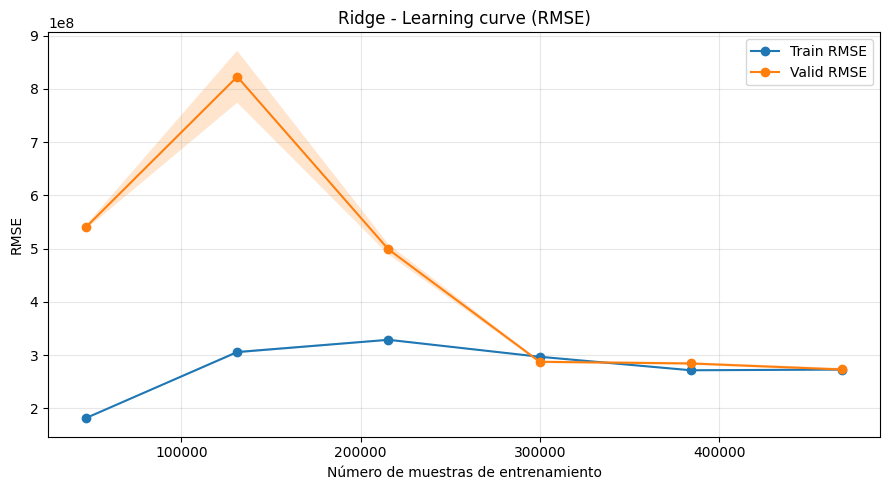

In [ ]:
# Ejemplo de uso:
plot_learning_curve_regression(ridge, Xt_train_sel, y_train, title="Ridge - Learning curve (RMSE)")

## 8. Random Forest regularizado

In [ ]:
from sklearn.preprocessing import OrdinalEncoder
# num: solo imputación (no scaler)
num_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
])

# cat: ordinal encoding (NO one-hot)
cat_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ord", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_tree, num_vars_present + ord_in_num),
        ("cat", cat_tree, cat_vars_present_all),
    ],
    remainder="drop"
)


In [ ]:

rf_fast = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,       # empieza bajo (100-300)
        max_depth=18,           # límite de profundidad (muy importante)
        min_samples_leaf=10,    # estabiliza + acelera
        max_features="sqrt",
        bootstrap=True,
        max_samples=0.7,        # cada árbol ve solo 70% de filas
        n_jobs=-1,
        random_state=42,
        verbose=1               # ver progreso
    ))
])

rf_fast.fit(X_tr, y_tr)
pred = rf_fast.predict(X_te)
rmse = np.sqrt(mean_squared_error(y_te, pred))
mae = mean_absolute_error(y_te, pred)
r2 = r2_score(y_te, pred)

y_mean = y_te.mean()
umbral20_cop = y_mean * 0.20
nmae_mean = mae / y_mean

print(f"RF -> RMSE: {rmse:,.2f} | MAE: {mae:,.2f} | R2: {r2:.4f}")
print("\n=== Meta <20% (normalizada por promedio) ===")
print(f"Precio promedio (mean): {y_mean:,.0f} COP")
print(f"20% del promedio      : {umbral20_cop:,.0f} COP")
print(f"NMAE_mean             : {nmae_mean*100:.2f}%  (= MAE / mean)")
print("Cumple <20%?:", "SI" if nmae_mean <= 0.20 else "NO")

metrics_rf = evaluate_regression(y_test, pred, 'RandomForest', y_reference_mean=y_train.mean())
metrics_rf

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 196 tasks      | elapsed:  3.9min
[Parallel(n_jobs=-1)]: Done 200 out of 200 | elapsed:  3.9min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.4s


RF -> RMSE: 62,257,064.93 | MAE: 39,447,318.65 | R2: 0.9877

=== Meta <20% (normalizada por promedio) ===
Precio promedio (mean): 468,715,535 COP
20% del promedio      : 93,743,107 COP
NMAE_mean             : 8.42%  (= MAE / mean)
Cumple <20%?: SI


[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    1.9s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    1.9s finished


,modelo,MAE,RMSE,R2,NMAE_mean
0,RandomForest,"39,447,318.65","62,257,064.93",0.99,0.08


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

rf_fast = Pipeline(steps=[
    ("preprocessor", tree_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=50,       # empieza bajo (100-300)
        max_depth=10,           # límite de profundidad (muy importante)
        max_samples=0.3,        # cada árbol ve solo 70% de filas
        n_jobs=-1,
        random_state=42,
        verbose=1               # ver progreso
    ))
])

rf_fast.fit(X_tr, y_tr)
pred = rf_fast.predict(X_te)
rmse = np.sqrt(mean_squared_error(y_te, pred))
mae = mean_absolute_error(y_te, pred)
r2 = r2_score(y_te, pred)

y_mean = y_te.mean()
umbral20_cop = y_mean * 0.20
nmae_mean = mae / y_mean

print(f"RF -> RMSE: {rmse:,.2f} | MAE: {mae:,.2f} | R2: {r2:.4f}")
print("\n=== Meta <20% (normalizada por promedio) ===")
print(f"Precio promedio (mean): {y_mean:,.0f} COP")
print(f"20% del promedio      : {umbral20_cop:,.0f} COP")
print(f"NMAE_mean             : {nmae_mean*100:.2f}%  (= MAE / mean)")
print("Cumple <20%?:", "SI" if nmae_mean <= 0.20 else "NO")

metrics_rf = evaluate_regression(y_test, pred, 'RandomForest', y_reference_mean=y_train.mean())
metrics_rf

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:  2.8min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.


RF -> RMSE: 110,008,416.67 | MAE: 71,288,738.29 | R2: 0.9616

=== Meta <20% (normalizada por promedio) ===
Precio promedio (mean): 468,715,535 COP
20% del promedio      : 93,743,107 COP
NMAE_mean             : 15.21%  (= MAE / mean)
Cumple <20%?: SI


[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done  50 out of  50 | elapsed:    0.3s finished


,modelo,MAE,RMSE,R2,NMAE_mean
0,RandomForest,"71,288,738.29","110,008,416.67",0.96,0.14


## 9. XGBoost

In [ ]:

xgb = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

xgb.fit(
    Xt_train_sel,
    y_train,
    eval_set=[(Xt_train_sel, y_train), (Xt_test_sel, y_test)],
    verbose=False
)

pred_xgb = xgb.predict(Xt_test_sel)
metrics_xgb = evaluate_regression(y_test, pred_xgb, 'XGBoost', y_reference_mean=y_train.mean())
metrics_xgb


,modelo,MAE,RMSE,R2,NMAE_mean
0,XGBoost,"58,909,557.06","88,431,708.18",0.98,0.12


In [ ]:
from xgboost import XGBRegressor
from sklearn.model_selection import cross_val_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1) Preprocesa una sola vez (espacio de features fijo)
preprocessor_present.fit(X_tr)
Xt_tr = preprocessor_present.transform(X_tr)
Xt_te = preprocessor_present.transform(X_te)

# 2) Aplica la máscara (debe coincidir con Xt_tr.shape[1])
assert Xt_tr.shape[1] == len(mask_sel), (Xt_tr.shape[1], len(mask_sel))
Xt_tr_sel = Xt_tr[:, mask_sel]
Xt_te_sel = Xt_te[:, mask_sel]

# 3) Modelo
xgb = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    tree_method="hist",
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

# 4) CV sobre matriz ya transformada/seleccionada
cv_scores = cross_val_score(xgb, Xt_tr_sel, y_tr, cv=5, scoring="r2", n_jobs=1)
print(f"CV R²: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

# 5) Fit final y test
xgb.fit(Xt_tr_sel, y_tr)
print(f"Train R²: {xgb.score(Xt_tr_sel, y_tr):.4f}")
print(f"Test R²:  {xgb.score(Xt_te_sel, y_te):.4f}")


# 6) Predicciones
pred_tr = xgb.predict(Xt_tr_sel)
pred_te = xgb.predict(Xt_te_sel)

# 7) Métricas
rmse_tr = np.sqrt(mean_squared_error(y_tr, pred_tr))
mae_tr  = mean_absolute_error(y_tr, pred_tr)
r2_tr   = r2_score(y_tr, pred_tr)

rmse_te = np.sqrt(mean_squared_error(y_te, pred_te))
mae_te  = mean_absolute_error(y_te, pred_te)
r2_te   = r2_score(y_te, pred_te)

y_mean = y_te.mean()
umbral20_cop = y_mean * 0.20
nmae_mean = mae_te / y_mean

print(f"Train -> RMSE: {rmse_tr:,.2f} | MAE: {mae_tr:,.2f} | R²: {r2_tr:.4f}")
print(f"Test  -> RMSE: {rmse_te:,.2f} | MAE: {mae_te:,.2f} | R²: {r2_te:.4f}")
print("\n=== Meta <20% (normalizada por promedio) ===")
print(f"Precio promedio (mean): {y_mean:,.0f} COP")
print(f"20% del promedio      : {umbral20_cop:,.0f} COP")
print(f"NMAE_mean             : {nmae_mean*100:.2f}%  (= MAE / mean)")
print("Cumple <20%?:", "SI" if nmae_mean <= 0.20 else "NO")
metrics_xgb = evaluate_regression(y_test, pred_xgb, 'XGBoost', y_reference_mean=y_train.mean())
metrics_xgb


CV R²: 0.5777 (+/- 0.3880)
Train R²: 0.9753
Test R²:  0.9752
Train -> RMSE: 91,675,205.70 | MAE: 60,820,114.15 | R²: 0.9753
Test  -> RMSE: 88,431,708.18 | MAE: 58,909,557.06 | R²: 0.9752

=== Meta <20% (normalizada por promedio) ===
Precio promedio (mean): 468,715,535 COP
20% del promedio      : 93,743,107 COP
NMAE_mean             : 12.57%  (= MAE / mean)
Cumple <20%?: SI


,modelo,MAE,RMSE,R2,NMAE_mean
0,XGBoost,"58,909,557.06","88,431,708.18",0.98,0.12


## 10. Consolidado de métricas

In [ ]:

metrics_all = pd.concat([metrics_ridge, metrics_rf, metrics_xgb], ignore_index=True)
metrics_all = metrics_all.sort_values(['R2', 'MAE'], ascending=[False, True]).reset_index(drop=True)
metrics_all.to_csv(RESULTS_DIR / 'metrics' / 'benchmark_modelos.csv', index=False)
metrics_all


,modelo,MAE,RMSE,R2,NMAE_mean
0,XGBoost,"58,909,557.06","88,431,708.18",0.98,0.12
1,RandomForest,"71,288,738.29","110,008,416.67",0.96,0.14
2,Ridge,"150,971,552.27","262,880,665.69",0.78,0.31


## 11. Validación por grupos

In [ ]:
cv_results = []
base_groups = X_train.copy()

for group_col in GROUP_COL_CANDIDATES:
    if group_col in base_groups.columns and base_groups[group_col].nunique() >= 5:
        # XGBoost group validation
        group_metrics_xgb = run_group_cv(xgb, Xt_train_sel, y_train, base_groups[group_col], f'XGBoost_{group_col}')
        cv_results.append(group_metrics_xgb)

        # Random Forest (rf_fast) group validation
        # For RF, we pass X_tr and y_tr directly since the preprocessor is part of the pipeline.
        group_metrics_rf = run_group_cv(rf_fast, X_tr, y_tr, base_groups[group_col], f'RandomForest_{group_col}')
        cv_results.append(group_metrics_rf)

cv_results_df = pd.concat(cv_results, ignore_index=True) if cv_results else pd.DataFrame()
cv_results_df.to_csv(RESULTS_DIR / 'metrics' / 'xgb_rf_group_cv.csv', index=False)
cv_results_df.head()

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:  2.2min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done  50 out of  50 | elapsed:    0.3s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done  50 out of  50 | elapsed:  2.2min finished
[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.3s
[Parallel(n_jobs=2)]: Done  50 out of  50 | elapsed:    0.3s finished
[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done  46 tasks      | elapsed:  2.1min
[Parall

,fold_r2,fold_mae,fold_rmse,fold_nmae_mean,modelo,grupo
0,0.88,"92,872,585.20","188,550,179.67",0.19,XGBoost_Codproyecto,Codproyecto
1,0.85,"100,109,602.80","247,680,876.80",0.20,XGBoost_Codproyecto,Codproyecto
2,0.87,"98,573,257.19","214,504,150.56",0.20,XGBoost_Codproyecto,Codproyecto
3,0.86,"92,875,551.60","211,165,774.45",0.19,XGBoost_Codproyecto,Codproyecto
4,0.88,"95,849,844.13","192,834,509.37",0.19,XGBoost_Codproyecto,Codproyecto


--- Resumen de Métricas de Validación Cruzada por Grupo ---
|                                             | ('fold_r2', 'mean')   | ('fold_r2', 'std')   | ('fold_mae', 'mean')   | ('fold_mae', 'std')   | ('fold_rmse', 'mean')   | ('fold_rmse', 'std')   | ('fold_nmae_mean', 'mean')   | ('fold_nmae_mean', 'std')   |
|:--------------------------------------------|:----------------------|:---------------------|:-----------------------|:----------------------|:------------------------|:-----------------------|:-----------------------------|:----------------------------|
| ('RandomForest_Codproyecto', 'Codproyecto') | 0.8208                | 0.0234               | 1.13044e+08            | 1.04501e+07           | 2.45851e+08             | 1.68074e+07            | 0.2289                       | 0.0212                      |
| ('RandomForest_Estrato', 'Estrato')         | 0.5081                | 0.2744               | 1.29384e+08            | 1.10315e+08           | 2.40129e+08             | 2.

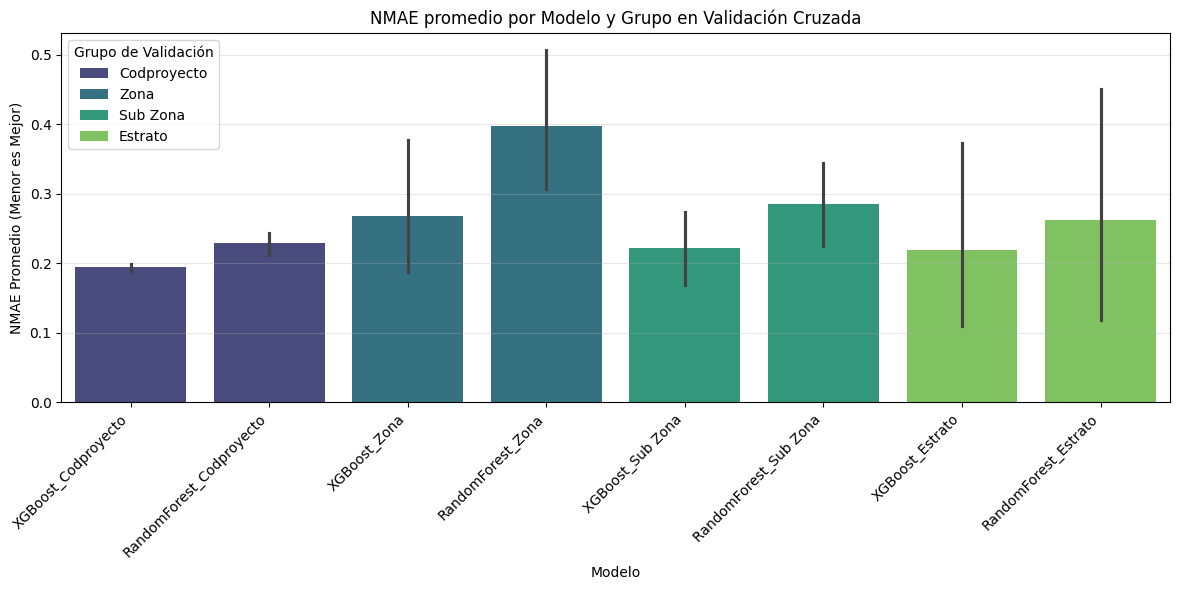

In [ ]:
print('--- Resumen de Métricas de Validación Cruzada por Grupo ---')
summary_cv = cv_results_df.groupby(['modelo', 'grupo'])[[
    'fold_r2', 'fold_mae', 'fold_rmse', 'fold_nmae_mean'
]].agg(['mean', 'std']).round(4)
print(summary_cv.to_markdown(numalign="left", stralign="left"))


plt.figure(figsize=(12, 6))
sns.barplot(data=cv_results_df, x='modelo', y='fold_nmae_mean', hue='grupo', palette='viridis')
plt.title('NMAE promedio por Modelo y Grupo en Validación Cruzada')
plt.ylabel('NMAE Promedio (Menor es Mejor)')
plt.xlabel('Modelo')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Grupo de Validación')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 12. SHAP para el modelo final

In [ ]:

explainer = shap.TreeExplainer(xgb)
X_shap = Xt_test_sel[:1000]
X_shap_dense = X_shap.toarray() if sparse.issparse(X_shap) else X_shap
shap_values = explainer.shap_values(X_shap)

shap_importance = pd.DataFrame({
    'feature': selected_features,
    'importance': np.abs(shap_values).mean(axis=0)
}).sort_values('importance', ascending=False)

shap_importance.to_csv(RESULTS_DIR / 'shap' / 'shap_feature_importance.csv', index=False)
shap_importance.head(20)


,feature,importance
1,num__Area,"98,746,544.00"
0,num__Estrato,"55,056,144.00"
27,num__baños_totales,"44,200,860.00"
23,num__Latitud (Coordenada Real),"32,458,072.00"
26,num__area_por_alcoba,"22,131,974.00"
49,cat__Valor Garaje Adicional_$0,"21,124,090.00"
33,cat__Zona_Chicó,"18,833,880.00"
46,cat__Garaje_Cub. Sencillo,"18,678,360.00"
25,num__ipc_rebase_100,"12,676,015.00"
42,cat__Estudio/Estar_Si,"12,474,508.00"


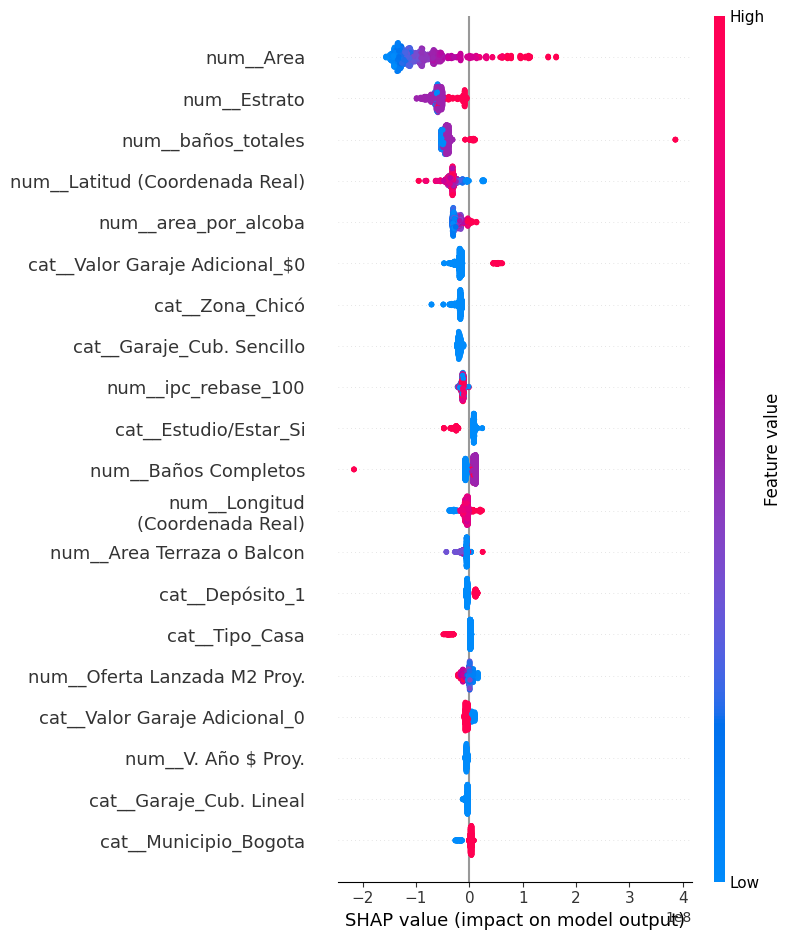

In [ ]:

shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=selected_features,
    max_display=20,
    show=True
)


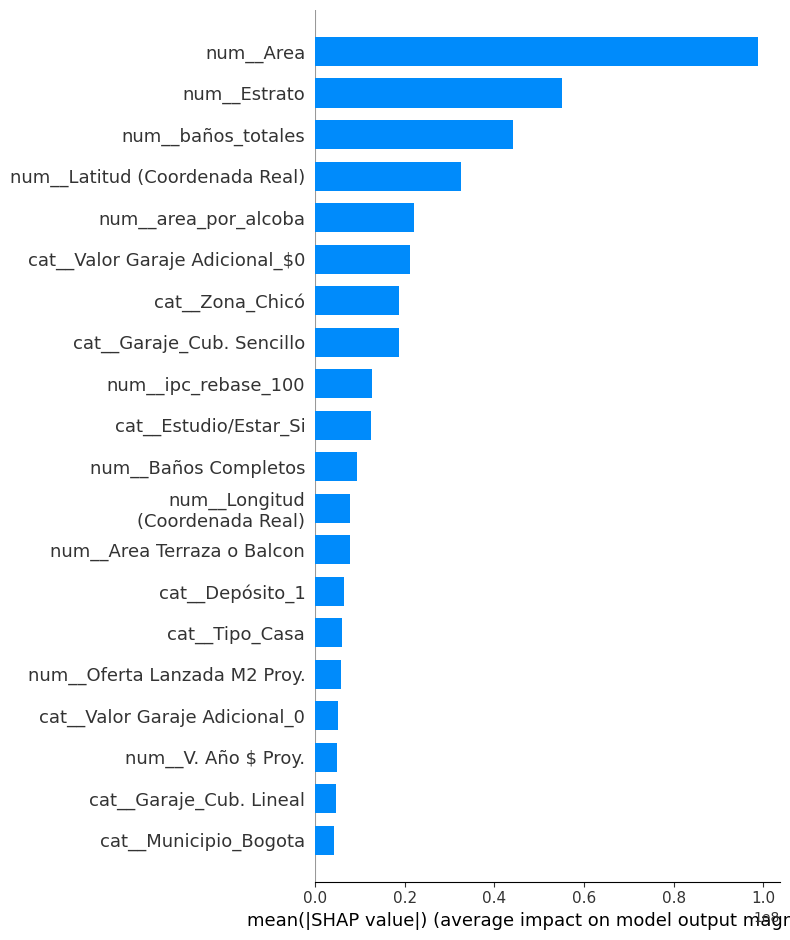

In [ ]:

shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=selected_features,
    plot_type='bar',
    max_display=20,
    show=True
)


## 13. Visualizaciones interpretativas del modelo final

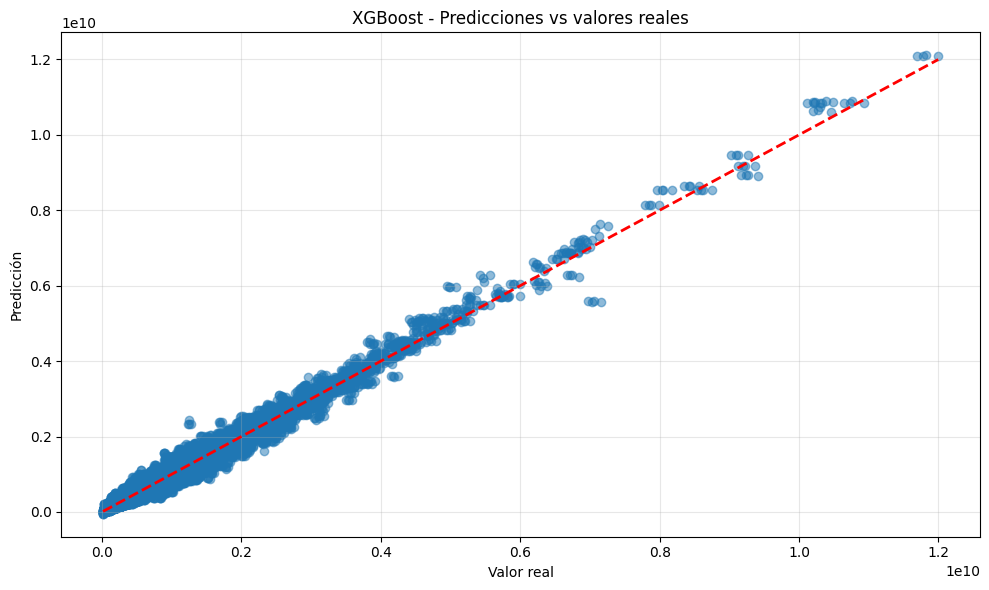

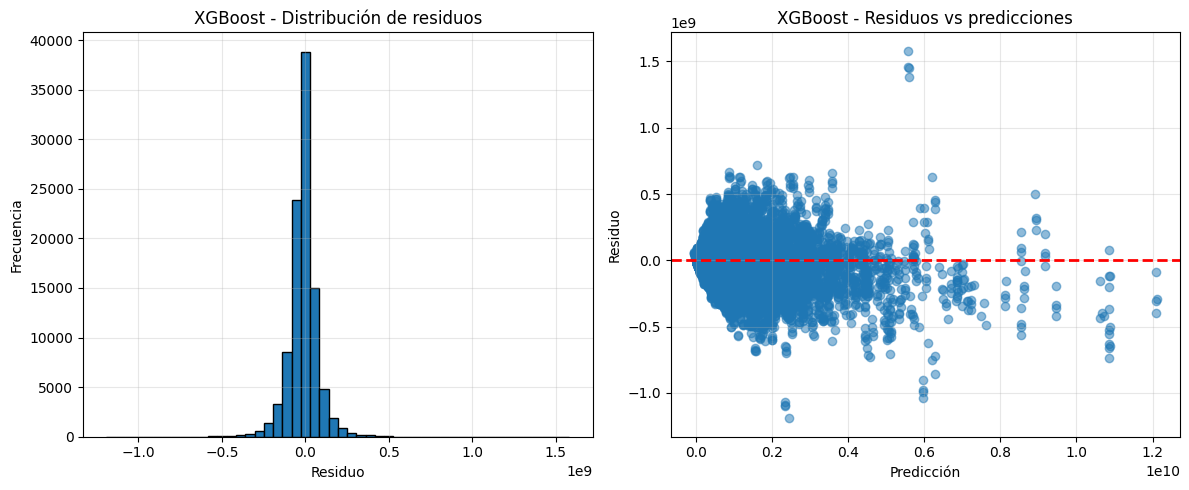

In [ ]:

plot_predictions_and_residuals(y_test, pred_xgb, 'XGBoost')


In [ ]:

feature_importance_xgb = pd.DataFrame({
    'feature': selected_features,
    'importance_xgb': xgb.feature_importances_
}).sort_values('importance_xgb', ascending=False)

comparison = feature_importance_xgb.merge(
    shap_importance,
    on='feature',
    how='outer'
).fillna(0)
comparison.head(20)


,feature,importance_xgb,importance
0,cat__# Gar._1,0.00,"2,356,712.50"
1,cat__# Gar._2,0.01,"2,058,387.62"
2,cat__# Gar._4,0.00,"1,073,605.50"
3,cat__Barrio_Cabrera,0.04,"1,824,206.88"
4,cat__Depósito_1,0.01,"6,438,629.50"
5,cat__Depósito_Si,0.00,"1,460,720.88"
6,cat__Estado_Term./,0.00,"4,166,448.75"
7,cat__Estudio/Estar_Estar,0.00,"1,467,740.12"
8,cat__Estudio/Estar_Estar y Estudio,0.00,"67,240.79"
9,cat__Estudio/Estar_Estudio,0.00,"325,812.94"



## 14. Notas de uso

- Esta versión evita celdas exploratorias intermedias que rompían la ejecución secuencial.
- Si quieres volverla todavía más robusta, el siguiente paso natural es mover estas funciones a un `.py` auxiliar.
- Si en tu entorno hay columnas opcionales que cambian entre corridas, se recomienda agregar validaciones explícitas por columna antes de cada bloque.
